### kilosort validation

In [1]:

from pathlib import Path
import numpy as np
import pandas as pd

from allensdk.brain_observatory.ecephys.ecephys_project_cache import EcephysProjectCache

cache_dir = Path("/Volumes/WD_BLACK/Spikes2Slope/allen_visual_coding_data")
results_dir = cache_dir.parent / "opto_results"

coding_cache = EcephysProjectCache.from_warehouse(
    manifest=str(cache_dir / "manifest.json")
)

opto_results = pd.read_csv(
    results_dir / "all_opto_unit_results.csv"
)

eligible = pd.read_csv(
    cache_dir.parent / "eligible_opto_sessions.csv"
)

print("Sessions:", opto_results["ecephys_session_id"].nunique())
print("Analyzed units:", len(opto_results))
print("Candidate optotagged units:", opto_results["candidate_tagged"].sum())
print("QC-matched candidates:", opto_results["matched_candidate"].sum())

assert opto_results["unit_id"].is_unique
assert opto_results["ecephys_session_id"].nunique() == 28
assert opto_results["matched_candidate"].sum() == 1127

display(opto_results.head())


/Users/keanuventura/miniforge3/envs/allen_env/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Sessions: 28
Analyzed units: 8579
Candidate optotagged units: 1152
QC-matched candidates: 1127


,unit_id,ecephys_session_id,specimen_id,cre_line,region,baseline_rate_hz,evoked_rate_hz,response_ratio,snr,amplitude_cutoff,presence_ratio,isi_violations,n_pulses,candidate_tagged,allen_qc,snr_qc,matched_candidate
0,950907555,721123822,707296982,Pvalb,VISam,0.000000,5.555556,5.555556,2.393214,0.059184,0.99,0.152776,45,True,True,True,True
1,950907350,721123822,707296982,Pvalb,VISam,0.000000,2.777778,2.777778,2.238972,0.013455,0.99,0.087777,45,True,True,True,True
2,950907356,721123822,707296982,Pvalb,VISam,2.777778,0.000000,0.000000,1.901291,0.070571,0.99,0.326987,45,False,True,True,False
3,950907360,721123822,707296982,Pvalb,VISam,0.000000,0.000000,0.000000,3.791406,0.021613,0.99,0.136268,45,False,True,True,False
4,950907364,721123822,707296982,Pvalb,VISam,0.000000,0.000000,0.000000,4.516170,0.006636,0.97,0.000000,45,False,True,True,False


### validate spike-sorted unit correspondence

In [3]:

allen_units = coding_cache.get_units()

comparison = opto_results.merge(
    allen_units[
        [
            "ecephys_session_id",
            "ecephys_structure_acronym",
            "snr",
            "amplitude_cutoff",
            "presence_ratio",
            "isi_violations"
        ]
    ].rename_axis("unit_id").reset_index(),
    on="unit_id",
    how="left",
    suffixes=("", "_allen"),
    validate="one_to_one",
    indicator=True
)


metrics = [
    "snr",
    "amplitude_cutoff",
    "presence_ratio",
    "isi_violations"
]

matched = comparison["_merge"] == "both"

validation = {
    "Missing Allen unit IDs": int((~matched).sum()),
    "Session mismatches": int((
        comparison.loc[matched, "ecephys_session_id"]
        != comparison.loc[matched, "ecephys_session_id_allen"]
    ).sum()),
    "Region mismatches": int((
        comparison.loc[matched, "region"]
        != comparison.loc[matched, "ecephys_structure_acronym"]
    ).sum())
}

for metric in metrics:
    mismatches = ~np.isclose(
        comparison.loc[matched, metric],
        comparison.loc[matched, f"{metric}_allen"],
        equal_nan=True
    )

    validation[f"{metric} mismatches"] = int(mismatches.sum())

validation_summary = pd.DataFrame(
    validation.items(),
    columns=["check", "mismatches"]
)

display(validation_summary)

validation_summary.to_csv(
    results_dir / "kilosort_unit_correspondence.csv",
    index=False
)


,check,mismatches
0,Missing Allen unit IDs,0
1,Session mismatches,0
2,Region mismatches,0
3,snr mismatches,0
4,amplitude_cutoff mismatches,0
5,presence_ratio mismatches,0
6,isi_violations mismatches,0


### spike-sorting quality

In [4]:

quality_metrics = [
    "snr",
    "isi_violations",
    "presence_ratio",
    "amplitude_cutoff"
]

candidates = opto_results[
    opto_results["candidate_tagged"]
].copy()

quality_summary = (
    candidates.groupby("snr_qc")[quality_metrics]
    .agg(["count", "median", "min", "max"])
)

print("Candidate units:", len(candidates))
print("Passing combined QC:", candidates["snr_qc"].sum())
print("Excluded by combined QC:", (~candidates["snr_qc"]).sum())

display(quality_summary)

quality_summary.to_csv(
    results_dir / "kilosort_quality_summary.csv"
)


Candidate units: 1152
Passing combined QC: 1127
Excluded by combined QC: 25


snr                               isi_violations                 \
       count    median       min       max          count    median  min   
snr_qc                                                                     
False     25  0.748629  0.181464  0.972812             25  0.104527  0.0   
True    1127  2.567552  1.001842  7.807041           1127  0.046609  0.0   

                 presence_ratio                    amplitude_cutoff            \
             max          count median   min   max            count    median   
snr_qc                                                                          
False   0.490839             25   0.99  0.95  0.99               25  0.017245   
True    0.499902           1127   0.99  0.95  0.99             1127  0.006899   

                            
             min       max  
snr_qc                      
False   0.000103  0.090535  
True    0.000001  0.099827

### candidate response strength

In [5]:

candidates = opto_results.loc[
    opto_results["matched_candidate"]
].copy()

candidates["evoked_spike_count"] = (
    candidates["evoked_rate_hz"]
    * candidates["n_pulses"]
    * 0.008
).round().astype(int)

candidates["baseline_spike_count"] = (
    candidates["baseline_rate_hz"]
    * candidates["n_pulses"]
    * 0.008
).round().astype(int)

print("QC-matched candidates:", len(candidates))

print("\nEvoked spike count distribution:")
display(
    candidates["evoked_spike_count"].describe(
        percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]
    )
)

print("\nCandidates with limited evoked spikes:")
for threshold in [1, 2, 5, 10]:
    count = (candidates["evoked_spike_count"] <= threshold).sum()
    print(f"At most {threshold} spikes: {count}")

print("\nMedian evoked spike counts by Cre line:")
display(
    candidates.groupby("cre_line")["evoked_spike_count"]
    .agg(["count", "median", "min", "max"])
)

candidates.to_csv(
    results_dir / "opto_candidate_response_strength.csv",
    index=False
)


QC-matched candidates: 1127

Evoked spike count distribution:


count    1127.000000
mean       14.511979
std        27.497482
min         1.000000
10%         1.000000
25%         2.000000
50%         4.000000
75%        10.500000
90%        47.000000
max       187.000000
Name: evoked_spike_count, dtype: float64


Candidates with limited evoked spikes:
At most 1 spikes: 261
At most 2 spikes: 425
At most 5 spikes: 687
At most 10 spikes: 845

Median evoked spike counts by Cre line:


,count,median,min,max
cre_line,,,,
Pvalb,345,9.0,1,184
Sst,535,3.0,1,187
Vip,247,3.0,1,148


### optogenetic response reliability

In [6]:

session_id = 829720705

session = coding_cache.get_session_data(session_id)

epochs = session.optogenetic_stimulation_epochs

pulses = epochs.loc[
    (epochs["stimulus_name"] == "pulse")
    & epochs["duration"].between(
        0.009, 0.020, inclusive="neither"
    )
]

starts = pulses["start_time"].to_numpy()

session_candidates = opto_results.loc[
    (opto_results["ecephys_session_id"] == session_id)
    & opto_results["matched_candidate"]
].copy()

reliability_results = []

for unit_id in session_candidates["unit_id"]:
    spikes = np.asarray(session.spike_times[unit_id])

    evoked_counts = (
        np.searchsorted(spikes, starts + 0.009)
        - np.searchsorted(spikes, starts + 0.001)
    )

    baseline_counts = (
        np.searchsorted(spikes, starts - 0.002)
        - np.searchsorted(spikes, starts - 0.010)
    )

    reliability_results.append({
        "unit_id": unit_id,
        "evoked_trial_fraction": np.mean(evoked_counts > 0),
        "baseline_trial_fraction": np.mean(baseline_counts > 0),
        "evoked_spike_count": int(evoked_counts.sum()),
        "baseline_spike_count": int(baseline_counts.sum()),
        "n_pulses": len(starts)
    })

reliability = pd.DataFrame(reliability_results)

print("Candidates evaluated:", len(reliability))

display(
    reliability[
        ["evoked_trial_fraction", "baseline_trial_fraction"]
    ].describe()
)

display(
    reliability.sort_values(
        "evoked_trial_fraction", ascending=False
    ).head(10)
)

reliability.to_csv(
    results_dir / f"opto_reliability_{session_id}.csv",
    index=False
)


/Users/keanuventura/miniforge3/envs/allen_env/lib/python3.10/site-packages/hdmf/spec/namespace.py:531: UserWarning: Ignoring cached namespace 'hdmf-common' version 1.1.3 because version 1.8.0 is already loaded.
  warn("Ignoring cached namespace '%s' version %s because version %s is already loaded."
/Users/keanuventura/miniforge3/envs/allen_env/lib/python3.10/site-packages/hdmf/spec/namespace.py:531: UserWarning: Ignoring cached namespace 'core' version 2.2.2 because version 2.6.0-alpha is already loaded.
  warn("Ignoring cached namespace '%s' version %s because version %s is already loaded."
/Users/keanuventura/miniforge3/envs/allen_env/lib/python3.10/site-packages/hdmf/spec/namespace.py:531: UserWarning: Ignoring cached namespace 'hdmf-common' version 1.1.3 because version 1.8.0 is already loaded.
  warn("Ignoring cached namespace '%s' version %s because version %s is already loaded."
/Users/keanuventura/miniforge3/envs/allen_env/lib/python3.10/site-packages/hdmf/spec/namespace.py:531

Candidates evaluated: 59


,evoked_trial_fraction,baseline_trial_fraction
count,59.000000,59.000000
mean,0.387571,0.070508
std,0.290328,0.074239
min,0.026667,0.000000
25%,0.106667,0.013333
50%,0.386667,0.066667
75%,0.680000,0.080000
max,1.000000,0.306667


,unit_id,evoked_trial_fraction,baseline_trial_fraction,evoked_spike_count,baseline_spike_count,n_pulses
12,951131589,1.000000,0.093333,174,7,75
0,951131470,0.933333,0.066667,178,5,75
46,951140617,0.853333,0.133333,158,11,75
25,951132224,0.840000,0.306667,141,24,75
4,951131506,0.826667,0.146667,95,11,75
18,951132054,0.800000,0.240000,119,21,75
51,951141065,0.800000,0.080000,105,6,75
3,951131522,0.733333,0.066667,103,6,75
49,951140832,0.720000,0.066667,98,5,75
19,951132138,0.706667,0.280000,79,24,75


### reliability distribution

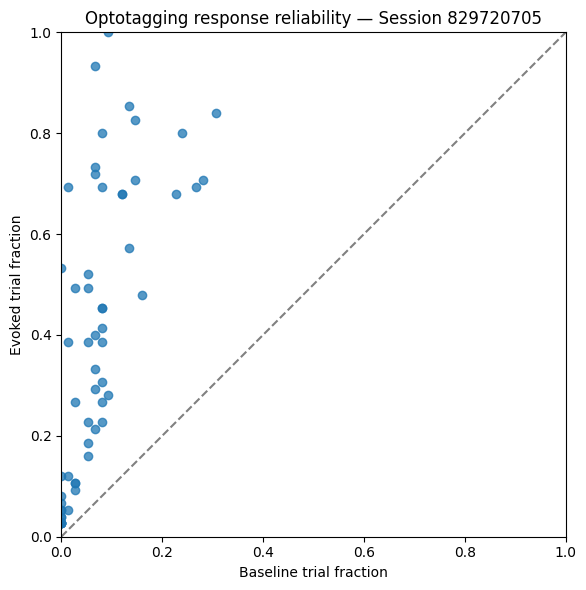

Candidates with higher evoked than baseline trial fraction: 59 of 59


In [7]:

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 6))

ax.scatter(
    reliability["baseline_trial_fraction"],
    reliability["evoked_trial_fraction"],
    alpha=0.75
)

ax.plot([0, 1], [0, 1], linestyle="--", color="gray")

ax.set(
    xlabel="Baseline trial fraction",
    ylabel="Evoked trial fraction",
    title="Optotagging response reliability — Session 829720705",
    xlim=(0, 1),
    ylim=(0, 1)
)

ax.set_aspect("equal")
plt.tight_layout()
plt.show()

print(
    "Candidates with higher evoked than baseline trial fraction:",
    (
        reliability["evoked_trial_fraction"]
        > reliability["baseline_trial_fraction"]
    ).sum(),
    "of",
    len(reliability)
)


### allen tutorial mean spike waveform examination

/Users/keanuventura/miniforge3/envs/allen_env/lib/python3.10/site-packages/hdmf/spec/namespace.py:531: UserWarning: Ignoring cached namespace 'hdmf-common' version 1.1.3 because version 1.8.0 is already loaded.
  warn("Ignoring cached namespace '%s' version %s because version %s is already loaded."
/Users/keanuventura/miniforge3/envs/allen_env/lib/python3.10/site-packages/hdmf/spec/namespace.py:531: UserWarning: Ignoring cached namespace 'core' version 2.2.2 because version 2.6.0-alpha is already loaded.
  warn("Ignoring cached namespace '%s' version %s because version %s is already loaded."


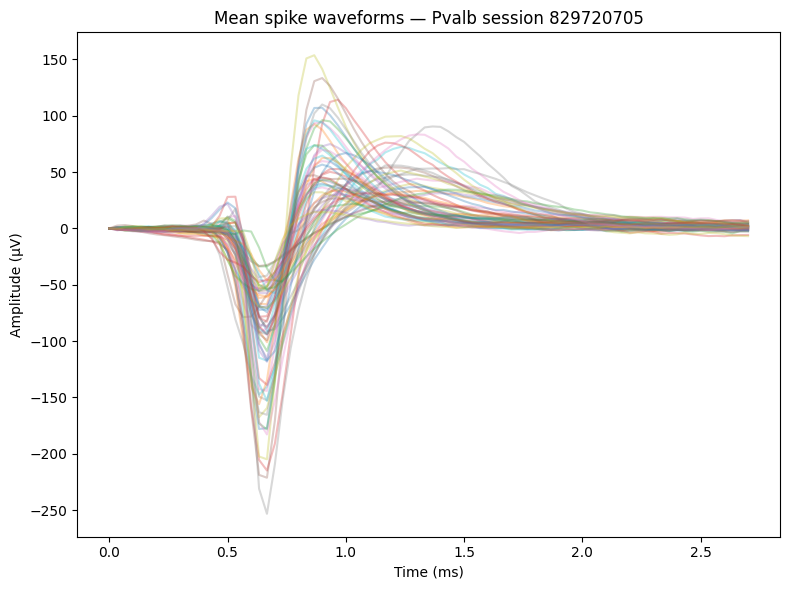

Candidate waveforms plotted: 59


In [8]:

session_candidates = opto_results.loc[
    (opto_results["ecephys_session_id"] == 829720705)
    & opto_results["matched_candidate"]
]

fig, ax = plt.subplots(figsize=(8, 6))

for unit_id in session_candidates["unit_id"]:
    peak_channel = session.units.loc[unit_id, "peak_channel_id"]
    waveform = session.mean_waveforms[unit_id].sel(
        channel_id=peak_channel
    )

    ax.plot(
        waveform.time.values * 1000,
        waveform.values,
        alpha=0.3
    )

ax.set(
    xlabel="Time (ms)",
    ylabel="Amplitude (µV)",
    title="Mean spike waveforms — Pvalb session 829720705"
)

plt.tight_layout()
plt.show()

print("Candidate waveforms plotted:", len(session_candidates))


### standout session

/Users/keanuventura/miniforge3/envs/allen_env/lib/python3.10/site-packages/hdmf/spec/namespace.py:531: UserWarning: Ignoring cached namespace 'hdmf-common' version 1.1.3 because version 1.8.0 is already loaded.
  warn("Ignoring cached namespace '%s' version %s because version %s is already loaded."
/Users/keanuventura/miniforge3/envs/allen_env/lib/python3.10/site-packages/hdmf/spec/namespace.py:531: UserWarning: Ignoring cached namespace 'core' version 2.2.2 because version 2.6.0-alpha is already loaded.
  warn("Ignoring cached namespace '%s' version %s because version %s is already loaded."
/Users/keanuventura/miniforge3/envs/allen_env/lib/python3.10/site-packages/hdmf/spec/namespace.py:531: UserWarning: Ignoring cached namespace 'hdmf-common' version 1.1.3 because version 1.8.0 is already loaded.
  warn("Ignoring cached namespace '%s' version %s because version %s is already loaded."
/Users/keanuventura/miniforge3/envs/allen_env/lib/python3.10/site-packages/hdmf/spec/namespace.py:531

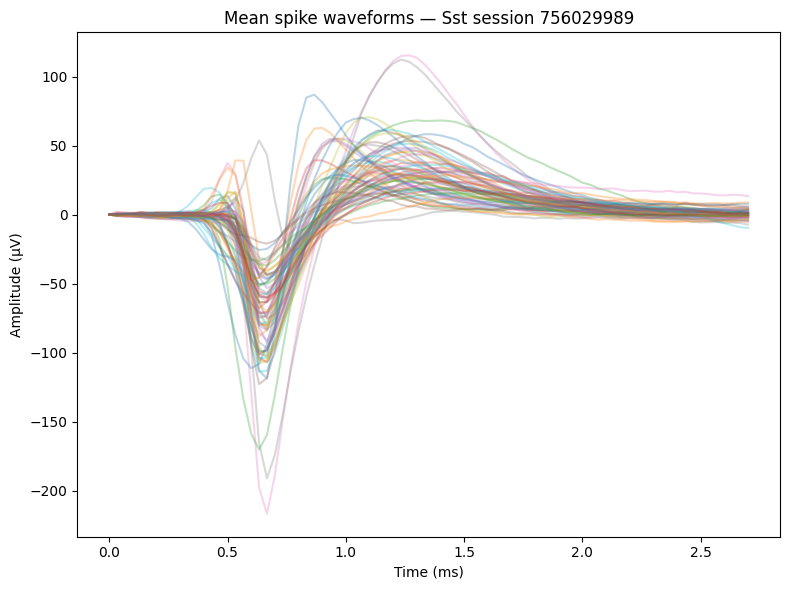

Candidate waveforms plotted: 66


In [9]:

session_id = 756029989

session = coding_cache.get_session_data(session_id)

session_candidates = opto_results.loc[
    (opto_results["ecephys_session_id"] == session_id)
    & opto_results["matched_candidate"]
]

fig, ax = plt.subplots(figsize=(8, 6))

for unit_id in session_candidates["unit_id"]:
    peak_channel = session.units.loc[unit_id, "peak_channel_id"]
    waveform = session.mean_waveforms[unit_id].sel(
        channel_id=peak_channel
    )

    ax.plot(
        waveform.time.values * 1000,
        waveform.values,
        alpha=0.3
    )

ax.set(
    xlabel="Time (ms)",
    ylabel="Amplitude (µV)",
    title=f"Mean spike waveforms — Sst session {session_id}"
)

plt.tight_layout()
plt.show()

print("Candidate waveforms plotted:", len(session_candidates))


Our optotagging candidates match Allen's spike-sorted metadata and exhibit plausible mean waveforms, but the response-strength audit identified many weakly supported candidates. We need to distinguish those from convincingly light-driven units before using the optotagging labels in our main Spikes2Slope analysis